In [2]:
import sys
import torch

print("Python executable:", sys.executable)
print("Torch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


Python executable: c:\Users\Admin\Desktop\iitb_fellowship\venv\Scripts\python.exe
Torch version: 2.7.1+cu118
CUDA available: True
GPU: NVIDIA RTX 4500 Ada Generation


In [3]:
import os
import random
import shutil
from glob import glob

import cv2
import numpy as np
import matplotlib.pyplot as plt

RAW_DIR = "../data/raw/PlantVillage"
TRAIN_DIR = "../data/train"
VAL_DIR   = "../data/val"
TEST_DIR  = "../data/test"

VALID_EXTENSIONS = (".jpg", ".jpeg", ".png")

In [4]:
print("RAW_DIR exists:", os.path.exists(RAW_DIR))
print("Folders inside RAW_DIR:")
print(os.listdir(RAW_DIR))


RAW_DIR exists: True
Folders inside RAW_DIR:
['Pepper__bell___Bacterial_spot', 'Pepper__bell___healthy', 'Potato___Early_blight', 'Potato___healthy', 'Potato___Late_blight', 'Tomato_Bacterial_spot', 'Tomato_Early_blight', 'Tomato_healthy', 'Tomato_Late_blight', 'Tomato_Leaf_Mold', 'Tomato_Septoria_leaf_spot', 'Tomato_Spider_mites_Two_spotted_spider_mite', 'Tomato__Target_Spot', 'Tomato__Tomato_mosaic_virus', 'Tomato__Tomato_YellowLeaf__Curl_Virus']


In [5]:
tomato_classes = []

for cls in os.listdir(RAW_DIR):
    cls_path = os.path.join(RAW_DIR, cls)
    if cls.startswith("Tomato") and os.path.isdir(cls_path):
        img_count = len([
            f for f in os.listdir(cls_path)
            if f.lower().endswith(VALID_EXTENSIONS)
        ])
        if img_count > 0:
            tomato_classes.append(cls)

print(f"Tomato classes found ({len(tomato_classes)}):")
for cls in tomato_classes:
    print(cls)


Tomato classes found (10):
Tomato_Bacterial_spot
Tomato_Early_blight
Tomato_healthy
Tomato_Late_blight
Tomato_Leaf_Mold
Tomato_Septoria_leaf_spot
Tomato_Spider_mites_Two_spotted_spider_mite
Tomato__Target_Spot
Tomato__Tomato_mosaic_virus
Tomato__Tomato_YellowLeaf__Curl_Virus


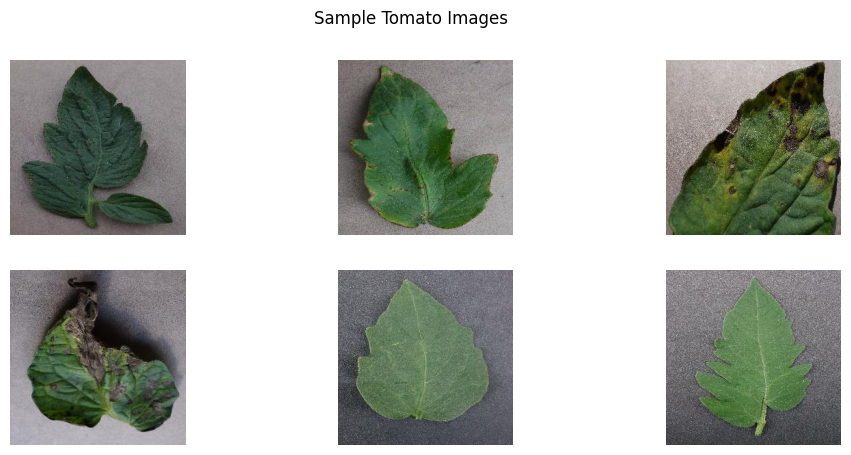

In [6]:
sample_paths = []

for cls in tomato_classes[:3]:
    imgs = glob(os.path.join(RAW_DIR, cls, "*"))
    sample_paths.extend(imgs[:2])

plt.figure(figsize=(12, 5))
for i, img_path in enumerate(sample_paths):
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    plt.subplot(2, 3, i + 1)
    plt.imshow(img)
    plt.axis("off")

plt.suptitle("Sample Tomato Images")
plt.show()


In [7]:
for folder in [TRAIN_DIR, VAL_DIR, TEST_DIR]:
    if os.path.exists(folder):
        shutil.rmtree(folder)
    os.makedirs(folder)

print("Clean train / val / test directories created")


Clean train / val / test directories created


In [8]:
TRAIN_RATIO = 0.7
VAL_RATIO   = 0.15
def split_and_copy(class_name):
    src_dir = os.path.join(RAW_DIR, class_name)
    images = [
        f for f in os.listdir(src_dir)
        if f.lower().endswith(VALID_EXTENSIONS)
    ]

    random.shuffle(images)

    n_total = len(images)
    n_train = int(n_total * TRAIN_RATIO)
    n_val   = int(n_total * VAL_RATIO)

    splits = {
        "train": images[:n_train],
        "val":   images[n_train:n_train + n_val],
        "test":  images[n_train + n_val:]
    }

    for split, files in splits.items():
        dst_dir = os.path.join(f"../data/{split}", class_name)
        os.makedirs(dst_dir, exist_ok=True)

        for img in files:
            shutil.copy(
                os.path.join(src_dir, img),
                os.path.join(dst_dir, img)
            )

    return {k: len(v) for k, v in splits.items()}


In [9]:
stats = {}

for cls in tomato_classes:
    stats[cls] = split_and_copy(cls)

print("Dataset split completed\n")

for cls, s in stats.items():
    print(f"{cls}: {s}")


Dataset split completed

Tomato_Bacterial_spot: {'train': 1488, 'val': 319, 'test': 320}
Tomato_Early_blight: {'train': 700, 'val': 150, 'test': 150}
Tomato_healthy: {'train': 1113, 'val': 238, 'test': 240}
Tomato_Late_blight: {'train': 1336, 'val': 286, 'test': 287}
Tomato_Leaf_Mold: {'train': 666, 'val': 142, 'test': 144}
Tomato_Septoria_leaf_spot: {'train': 1239, 'val': 265, 'test': 267}
Tomato_Spider_mites_Two_spotted_spider_mite: {'train': 1173, 'val': 251, 'test': 252}
Tomato__Target_Spot: {'train': 982, 'val': 210, 'test': 212}
Tomato__Tomato_mosaic_virus: {'train': 261, 'val': 55, 'test': 57}
Tomato__Tomato_YellowLeaf__Curl_Virus: {'train': 2245, 'val': 481, 'test': 482}


In [10]:
for split in ["train", "val", "test"]:
    path = f"../data/{split}"
    print(split, "classes:", len(os.listdir(path)))


train classes: 10
val classes: 10
test classes: 10


In [11]:
with open("../data/tomato_classes.txt", "w") as f:
    for cls in tomato_classes:
        f.write(cls + "\n")

print("Class names saved to data/tomato_classes.txt")


Class names saved to data/tomato_classes.txt
